## GENeSYS-MOD RES Tool - SINGAPORE (proof of concept, APAC hub geometry)

Singapore as a single national node, run out of the shared APAC hub region file
(`fel_APAC_regions.geojson`, 18 countries at country level, a `region` column ->
region-geojson workflow). This is the proof-of-concept run before scaling to the
full 18-country hub; the hub-wide data layers (EEZ, bathymetry, land cover, protected
areas) are already built for every APAC tile, this notebook just selects Singapore.

Onshore PV/wind + rooftop + offshore wind (Singapore's EEZ is tiny, ~675 km^2, so
offshore wind potential will be negligible - the pipeline still runs cleanly end to
end, which is the point of the smoke test).

**Important - explicit cutout corners, not `regions=`:** `fel_APAC_regions.geojson`
spans the whole APAC hub (88-179 E, -55-46 N). For a region-geojson, `get_cutout`
ignores `regions=` and sizes the cutout off the WHOLE file
(`_determine_cutout_bounds`) - so running Singapore with the default `regions=[]`
would try to build a continent-scale cutout. Instead this notebook passes explicit
`cutout_north_west`/`cutout_south_east` corners around Singapore's bbox (+1 deg pad),
the same mechanism `run_batch_by_tile` uses per tile - see CLAUDE.md "Per-tile bbox
via explicit corners". `get_coords`/`get_region_shapes` still use `regions=['SG']` to
pick Singapore's polygon out of the 18-country file once the cutout exists.

Data layers (built for the full APAC hub, reused as-is for this single-region run):
- **regions**: `geodata/regions/fel_APAC_regions.geojson` (18 countries, `region` = ISO-A2-ish
  code, e.g. SG/ID/MY/...). admin=0 (country level, the only level provided).
- **land cover**: ESA WorldCover 2021 v200, built PER TILE (not hub-wide - the hub is
  bigger than Europe, so one global raster would mean ~1000+ 10 m source tiles).
  Singapore sits in the `maritime_sea` tile (MY/SG/BN/ID/TL) ->
  `build_worldcover_apac.py maritime_sea` -> `worldcover_apac_maritime_sea_300m.tif`.
- **protected areas**: `build_wdpa_apac.py` -> `wdpa_apac.gpkg` (layer `wdpa`), the
  WDPA global pack filtered to the APAC hub bbox + strict IUCN tier (Ia/Ib/II).
- **EEZ**: `build_eez_apac.py` -> `eez_apac.geojson` (hub-wide, clipped to the hub
  bbox + simplified - Indonesia's archipelagic EEZ is ~368k vertices unsimplified,
  which GDAL's GeoJSON reader refuses outright).
- **bathymetry**: `build_bathymetry_apac.py` -> `bathymetry_apac_maritime_sea.nc`
  (GMRT GridServer over the maritime_sea tile bbox).

**Scaling to all 18 countries**: see `GENeSYS-MOD_RES_Tool_APAC.ipynb` (the
tile-batch driver, `run_batch_by_tile` over the 8 APAC tiles - mainland_sea,
maritime_sea, philippines, east_asia, south_asia, australia, new_zealand, png).

## General requirements & preparation

This timeseries script uses functions from atlite to generate weather timeseries for GENeSYS-MOD. It uses the ERA5 weather dataset, which is downloaded and transformed locally.

To use this script, you need to have the following packages installed:
- numpy
- matplotlib
- seaborn
- pandas / geopandas
- scikit-learn
- cartopy
- xarray
- atlite

In addition, in order to be able to load the ERA5 cutouts, you need an API key from https://cds.climate.copernicus.eu/user/register?destination=%2F%23!%2Fhome

To activate the API key, follow the instructions at https://cds.climate.copernicus.eu/api-how-to

For more information on how to run atlite, please refer to https://atlite.readthedocs.io/en/latest/

In [1]:
from functions import *

In [3]:
onshore_turbine = 'SiemensGamesa_SG_6.6_170_onshore'
offshore_turbine = 'SiemensGamesa_SG_14_236_offshore'
solar_panel = 'CdTe_inv95'

# APAC hub geometry (18 countries, region = ISO-A2-ish code). The 'region' column
# (no 'iso_a2') triggers the region-geojson workflow.
geo_file = "geodata/regions/fel_APAC_regions.geojson"
# EEZ: whole APAC hub, from Marine Regions EEZ v12, clipped to the hub bbox and
# simplified (build_eez_apac.py). _get_coords_custom clips it further to this run's
# own cutout bbox, so the hub-wide file is cheap to reuse for a single country.
offshore_file = "geodata/offshore/eez_apac.geojson"
# Bathymetry over the maritime_sea tile (MY/SG/BN/ID/TL) from the GMRT GridServer
# (build_bathymetry_apac.py). Singapore sits inside this tile's bbox.
bathymetry_file = "geodata/offshore/bathymetry_apac_maritime_sea.nc"

timeframe = "2018"   # one day to smoke-test; switch to "2018" for a full year
filename = "singapore"
output_dir = create_output_folder(timeframe)

admin = 0            # country level (the only level provided in fel_APAC_regions.geojson)
regions = ['SG']      # select Singapore out of the 18-country file

# Explicit cutout corners around Singapore's bbox (+1 deg pad), NOT regions=/geo_file
# bounds - see the markdown cell above. (lat, lon) each.
cutout_north_west = (2.47, 102.51)
cutout_south_east = (0.03, 105.13)

# --- Run switches (speed / navigation) ----------------------------------
# Skip the full-area capacity-factor timeseries block (PV/wind/heat) while
# iterating on the GIS potentials; set True for a full timeseries export.
generate_full_area_timeseries = True

# GIS availability: True = memory-safe per-region loop; False = single-pass. Only
# one region here, so either works - the per-region loop is still the recommended
# default (same code path as the full 18-country run).
run_GIS_analysis_by_region = True

# Availability-map colour: a hex (e.g. '#004664' -> white->navy ramp) or a named
# matplotlib colormap (e.g. 'Greens'). None = default Greens.
map_color = '#004664'

The output folder already exists.


In [4]:
# PV slope/azimuth for utility-scale (ground-mounted) PV.
pv_slope = 10          # near-equatorial (Singapore ~1.3 N): a low tilt is close to optimal
pv_azimuth = 180

# Optimal tilt: if True, utility-scale PV uses a per-coordinate optimal fixed
# tilt (function of latitude) and equator-facing azimuth instead of the single
# pv_slope/pv_azimuth above. Cheap closed-form rule (no per-angle yield search).
pv_optimal_tilt = True

# Rooftop PV, split like the model's P_PV_Rooftop_Residential / _Commercial. Each
# segment gets its own CF timeseries from a mix of panel orientations (tilt in
# degrees or "optimal"; azimuth "equator" = facing the equator per cell, "east",
# "west", or degrees from north) and a share of the rooftop potential.
# Residential roofs face wherever the house does; commercial roofs are mostly flat,
# so racks can face the equator at the optimal tilt.
rooftop_segments = {
    "residential": [{"tilt": 20, "azimuth": "equator", "weight": 0.5},
                    {"tilt": 20, "azimuth": "east", "weight": 0.25},
                    {"tilt": 20, "azimuth": "west", "weight": 0.25}],
    "commercial": [{"tilt": "optimal", "azimuth": "equator", "weight": 1.0}],
}
# Share of the rooftop potential per segment, per country, from GHSL built-up
# surface (geodata/config/rooftop_shares.csv, built by build_rooftop_shares.py).
rooftop_shares = load_rooftop_shares(regions)   # region codes are ISO2

# Usable-site thresholds: minimum developable share of a cutout cell for it
# to count as a usable location for the capacity-factor timeseries. Land is
# lenient (1%); rooftop is the built-up fraction (small everywhere, and Singapore
# is almost entirely built-up/urban), so it needs a higher bar to drop near-empty
# cells - raise if still too many.
usable_threshold = 0.01
usable_threshold_rooftop = 0.05

In [5]:
# Here, you need to define the horizontal and vertical distances (in degrees) between your coordinates
dx_step = 0.1
dy_step = 0.1

## Region Definition & Cutout preparation

Singapore is tiny (~0.5 deg x 0.5 deg); the default 0.275 deg ERA5-native resolution
used by the other APAC/India/Europe notebooks would only catch 1-2 grid cells here,
so this notebook uses a finer 0.1 deg grid instead - still coarser than the land-cover
raster, just enough to resolve the island with more than a couple of points.

Be aware that the first preparation of the cutout will take significant time!

In [6]:
# Pre-check the expected cutout size BEFORE downloading anything: grid cells,
# hourly time steps and total data points. Uses the SAME explicit corners as
# get_cutout below (regions=/geo_file bounds are NOT used when corners are given).
estimate_cutout_size(timeframe, cutout_north_west=cutout_north_west,
                     cutout_south_east=cutout_south_east, dx=dx_step, dy=dy_step)

Expected cutout size:
  bounds (lon/lat) : [102.51, 105.13] x [0.03, 2.47]
  grid             : 26 x 24 = 624 cells  (dx=0.1, dy=0.1)
  time steps       : 8,760 hourly  (2018)
  points/variable  : 5,466,240
  total points     : 60,128,640  (x11 variables)
  uncompressed     : ~240.5 MB float32 (on-disk .nc is far smaller, compressed)


{'nx': 26,
 'ny': 24,
 'n_cells': 624,
 'n_time': 8760,
 'points_per_var': 5466240,
 'total_points': 60128640,
 'raw_gb': 0.24051456}

In [7]:
cutout = get_cutout(filename,
                    timeframe,
                    cutout_north_west=cutout_north_west,
                    cutout_south_east=cutout_south_east,
                    dx=dx_step,
                    dy=dy_step)

INFO:atlite.cutout:Building new cutout cutouts\singapore_2018_10_10.nc
INFO:atlite.data:Storing temporary files in C:\Users\Z0057UHE\AppData\Local\Temp\tmpjr26xrre
INFO:atlite.data:Calculating and writing with module era5:
INFO:atlite.datasets.era5:Requesting data for feature temperature...


cutouts/singapore_2018_10_10
Expected cutout size:
  bounds (lon/lat) : [102.51, 105.13] x [0.03, 2.47]
  grid             : 26 x 24 = 624 cells  (dx=0.1, dy=0.1)
  time steps       : 8,760 hourly  (2018)
  points/variable  : 5,466,240
  total points     : 60,128,640  (x11 variables)
  uncompressed     : ~240.5 MB float32 (on-disk .nc is far smaller, compressed)


INFO:atlite.datasets.era5:Requesting data for feature influx...
INFO:atlite.datasets.era5:Requesting data for feature height...
INFO:atlite.datasets.era5:CDS: reusing cached download for geopotential (['2018']-['01'])
INFO:atlite.datasets.era5:Requesting data for feature wind...
INFO:atlite.datasets.era5:CDS: downloading 2m_temperature, soil_temperature_level_4, 2m_dewpoint_temperature (['2018']-['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12'])
INFO:multiurl.base:Downloading https://object-store.os-api.cci2.ecmwf.int:443/cci2-prod-cache-1/2026-10-13/99a92781f0a3602c7d66dacaef288867.grib
INFO:atlite.datasets.era5:CDS: downloading 10m_u_component_of_wind, 10m_v_component_of_wind, 100m_u_component_of_wind, 100m_v_component_of_wind, forecast_surface_roughness (['2018']-['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12'])
INFO:multiurl.base:Downloading https://object-store.os-api.cci2.ecmwf.int:443/cci2-prod-cache-2/2026-10-13/3fdf20279b447f084c2

Plotting your cutout to ensure that everything is correct!

You can add zoom=True/False to zoom into your selection and use size to set the size of the graph if needed.

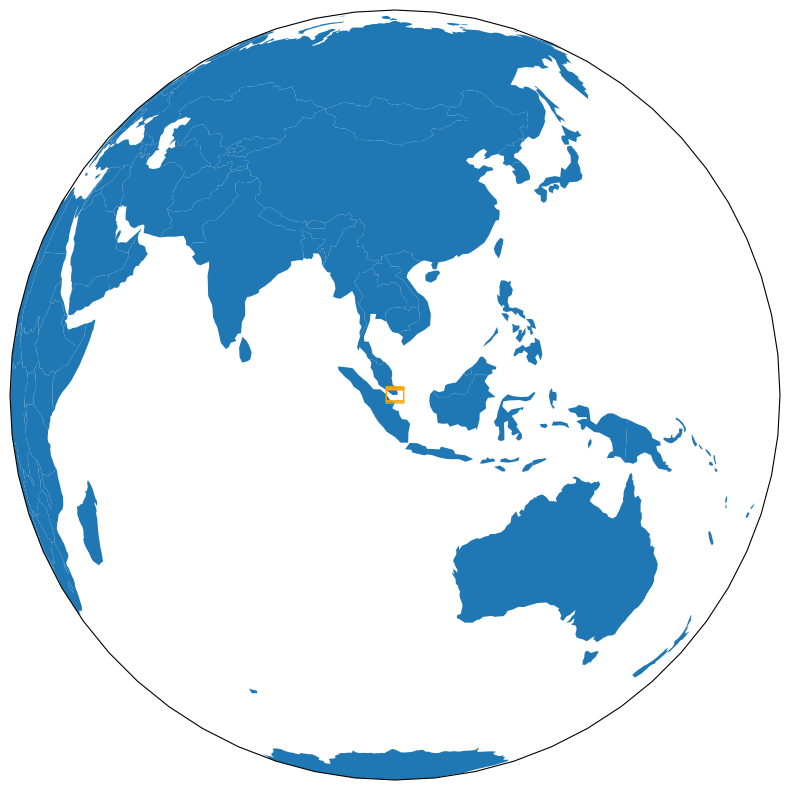

In [8]:
plot_country_map(cutout) # plot_country_map(cutout,zoom=False,size=8)

## General settings and functions

Always run these to create the relevant data entries.

In [9]:
# Offshore enabled: EEZ (eez_apac, clipped to this cutout's bbox) + GMRT depth ->
# coords_offshore populated. Singapore's EEZ is tiny (~675 km^2), so expect very few
# offshore cells.
coords_onshore, coords_offshore = get_coords(cutout,
                                             regions,
                                             geo_file,
                                             admin=admin,
                                             offshore_file=offshore_file,
                                             bathymetry_file=bathymetry_file)

## Functions for timeseries generation

In [10]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    pv_inf, pv_avg, pv_opt = pv_capacity_factors(cutout,
                                                 coords_onshore,
                                                 solar_panel,
                                                 pv_slope=pv_slope,
                                                 pv_azimuth=pv_azimuth,
                                                 optimal_tilt=pv_optimal_tilt,
                                                 timeframe=timeframe,
                                                 filename=filename,
                                                 write_raw_data=False,
                                                 output_dir=output_dir)

In [11]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    pv_tra = pv_capacity_factors(cutout,
                                 coords_onshore,
                                 solar_panel,
                                 tracking="horizontal",
                                 pv_azimuth=0, #refers to oriantation of the axis in this case
                                 timeframe=timeframe,
                                 filename=filename,
                                 write_raw_data=False,
                                 output_dir=output_dir)

In [12]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    display(pv_inf.mean())
    display(pv_avg.mean())
    display(pv_opt.mean())

region
SG    0.192944
dtype: float64

region
SG    0.19554
dtype: float64

region
SG    0.198724
dtype: float64

In [13]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    display(pv_tra.mean())

region
SG    0.229434
dtype: float64

In [14]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    wind_onshore_inf, wind_onshore_avg, wind_onshore_opt = wind_onshore_capacity_factors(cutout,
                                                                                         coords_onshore,
                                                                                         onshore_turbine,
                                                                                         timeframe=timeframe,
                                                                                         filename=filename,
                                                                                         write_raw_data=False,
                                                                                         output_dir=output_dir)

In [15]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    display(wind_onshore_inf.mean())
    display(wind_onshore_avg.mean())
    display(wind_onshore_opt.mean())

region
SG    0.065358
dtype: float64

region
SG    0.07846
dtype: float64

region
SG    0.089718
dtype: float64

In [16]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    wind_offshore_shallow, wind_offshore_transitional, wind_offshore_deep = wind_offshore_capacity_factors(cutout,
                                                                                                           coords_offshore,
                                                                                                           offshore_turbine,
                                                                                                           timeframe=timeframe,
                                                                                                           filename=filename,
                                                                                                           write_raw_data=False,
                                                                                                           output_dir=output_dir)

In [17]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    display(wind_offshore_shallow.mean())
    display(wind_offshore_transitional.mean())
    display(wind_offshore_deep.mean())

Series([], dtype: float64)

region
SG    0.13166
dtype: float64

region
SG    0.135632
dtype: float64

In [18]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    df_heatpump_ground_cop, df_cooling, df_heating, df_heatpump_cop = temperature_timeseries(cutout,
                                                                                            coords_onshore,
                                                                                            timeframe=timeframe,
                                                                                            filename=filename,
                                                                                            write_raw_data=False,
                                                                                            output_dir=output_dir)

In [19]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    display(df_heatpump_ground_cop.mean())
    display(df_heatpump_cop.mean())
    display(df_cooling.mean())
    display(df_heating.mean())

region
SG    0.079634
dtype: float32

region
SG    0.084685
dtype: float32

region
SG    5.21073
dtype: float32

Series([], dtype: float64)

# GIS-based renewable energy potentials

##### This part is still somewhat experimental. It uses functionality from the Atlite package to calculate available capcities for utility-scale PV, onshore wind, and rooftop PV installations.
##### It uses the information from the timeseries part to compute the shapefiles, the only thing that needs to be provided is the excluder zones (e.g. WDPA for protected areas). CORINE is provided for land cover in Europe, anything else would need to be separately downloaded.

In [20]:
# Region-agnostic: use the SAME region polygons as the timeseries (onshore),
# not the country/NUTS workflow. Selects just Singapore's polygon out of the
# 18-country hub file.
shapes, regions_name_en = get_region_shapes(geo_file, regions)

In [21]:
# --- Exclusion layers (SINGAPORE, via the maritime_sea APAC tile) ---------
# Region-agnostic builders; only the paths/codes below are region-specific.
#
# Land cover: ESA WorldCover 2021 v200, maritime_sea tile (MY/SG/BN/ID/TL), merged +
# downsampled to ~300 m (build_worldcover_apac.py maritime_sea). It carries EPSG:4326.
# Classes: 10 tree, 20 shrubland, 30 grassland, 40 cropland, 50 built-up,
# 60 bare/sparse, 70 snow/ice, 80 water, 90 wetland, 95 mangrove, 100 moss/lichen
# (0 = ocean/nodata fill in the merged raster).
LANDCOVER = "geodata/landcover/worldcover_apac_maritime_sea_300m.tif"

# atlite's availability calc needs a PROJECTED (metre) analysis CRS. WorldCover is
# EPSG:4326 (degrees); used directly it collapses the raster window to ~1 cell and
# returns ZERO available land. Reproject the excluders to an equal-area CRS (auto
# LAEA centred on the region). See CLAUDE.md "projected-CRS" gotcha.
area_crs = equal_area_crs(shapes)

# STRICT land availability: exclude ocean/nodata(0), tree(10), cropland(40),
# built-up(50), water(80), wetland(90), mangrove(95). Singapore is almost entirely
# built-up/water/tree already - this list mainly matters once more APAC countries
# are added; keep bare/sparse(60) and grassland(30)/shrubland(20) developable.
# No snow/ice(70) relevant here (tropical). Drop cropland from the strict list if
# you want to allow agrivoltaics on any remaining farmland.
worldcover_exclude = [0, 10, 40, 50, 80, 90, 95]

# Protected areas: WDPA global pack filtered to the APAC hub bbox + strict IUCN
# tier (build_wdpa_apac.py -> wdpa_apac.gpkg, layer 'wdpa'). Singapore itself has
# only a handful of small reserves (e.g. Bukit Timah, Sungei Buloh).
PROTECTED       = "geodata/exclusions/wdpa_apac.gpkg"
PROTECTED_LAYER = "wdpa"
PROTECTED_QUERY = "IUCN_CAT in ['Ia', 'Ib', 'II'] and REALM in ['Terrestrial', 'Coastal']"

excluder = make_land_excluder(
    LANDCOVER, worldcover_exclude, crs=area_crs,
    protected_files=PROTECTED, protected_layer=PROTECTED_LAYER,
    protected_query=PROTECTED_QUERY,
)

# Rooftop proxy: WorldCover built-up class only (50). Singapore is heavily built-up,
# so expect a much larger rooftop-available share than typical.
cities = make_rooftop_excluder(LANDCOVER, [50], crs=area_crs)

# --- Offshore exclusion: same WDPA source, marine+coastal strict areas.
OFFSHORE_EXCLUDE_FILES = "geodata/exclusions/wdpa_apac.gpkg"
OFFSHORE_EXCLUDE_LAYER = "wdpa"
OFFSHORE_EXCLUDE_QUERY = "REALM in ['Marine', 'Coastal'] and IUCN_CAT in ['Ia', 'Ib', 'II']"


In [22]:
# Capacity densities (MW/km2) and the developable share of suitable area per tech.
# Placeholder figures (DEA 2030 utility-scale / generic) - swap for Singapore-specific
# assumptions (e.g. EMA/SolarRTS) once you have a source; land is so constrained here
# that these numbers matter less than the exclusion layers themselves.
pv_cap_per_sqkm = 81.5                  # MW  (DEA 2030 utility-scale)
pv_percent_land_available = 0.03        # share of suitable area
wind_cap_per_sqkm = 27                  # MW
wind_percent_land_available = 0.03      # share of suitable area
rooftop_cap_per_sqkm = 100              # MW
rooftop_percent_area_available = 0.05   # installable share of built-up area

## Compute area availability (single pass, memory intensive)

This will calculate available surface areas for onshore, offshore, and rooftops using the excluders specified. Memory-intensive, since it calculates it all at once. See below for per-region loop version.

In [23]:
# Controlled by '(not run_GIS_analysis_by_region)' switch (set in the config cell).
if (not run_GIS_analysis_by_region):
    AvailabilityMatrix = calculate_and_plot_available_area(admin,cutout,shapes,regions_name_en,excluder)

In [24]:
# Controlled by '(not run_GIS_analysis_by_region)' switch (set in the config cell).
if (not run_GIS_analysis_by_region):
    AvailabilityMatrix_Rooftop = calculate_and_plot_available_rooftops(admin,cutout,shapes,regions_name_en,cities)

In [25]:
# Controlled by '(not run_GIS_analysis_by_region)' switch (set in the config cell).
if (not run_GIS_analysis_by_region):
    output_df = calculate_capacity_potentials(cutout,coords_onshore,AvailabilityMatrix,AvailabilityMatrix_Rooftop,pv_cap_per_sqkm,pv_percent_land_available,wind_cap_per_sqkm,wind_percent_land_available,rooftop_cap_per_sqkm,rooftop_percent_area_available,rooftop_shares=rooftop_shares)

In [26]:
# Controlled by '(not run_GIS_analysis_by_region)' switch (set in the config cell).
if (not run_GIS_analysis_by_region):
    # here is the resulting DataFrame containing all the potentials and areas that have been calculated
    output_df

## Compute area availability (Memory-safe all-region run)

Only one region here (Singapore), so this is equivalent to the single-pass cell above
in effect, but it is the same code path the full 18-country APAC run uses -
`calculate_potentials_per_region` processes one region at a time (bounded raster
window), writes a per-region CSV plus a combined CSV, and returns one stitched
availability map. Reuses the same `excluder`/`cities` defined above.

Processing region: SG
offshore exclusion: dropped 0 of 48 cells


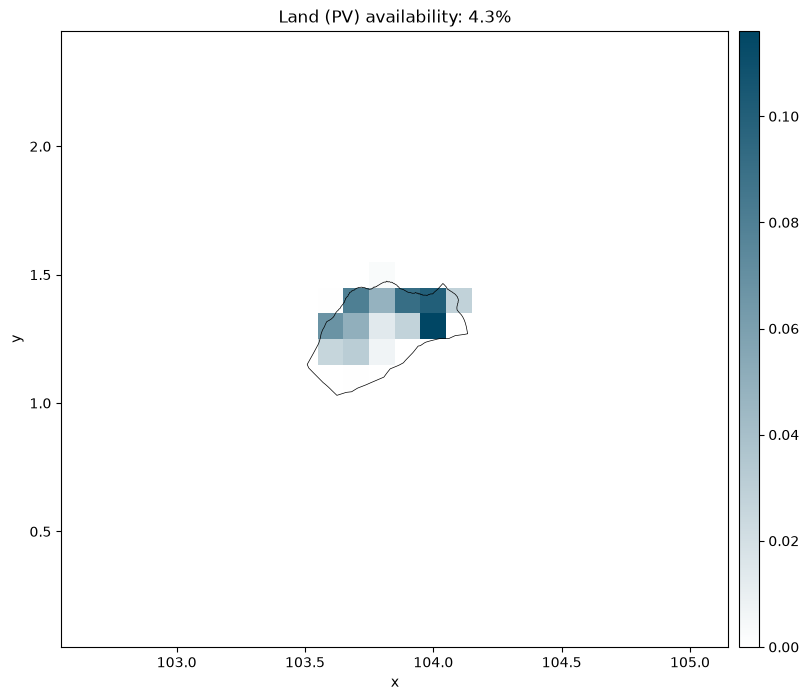

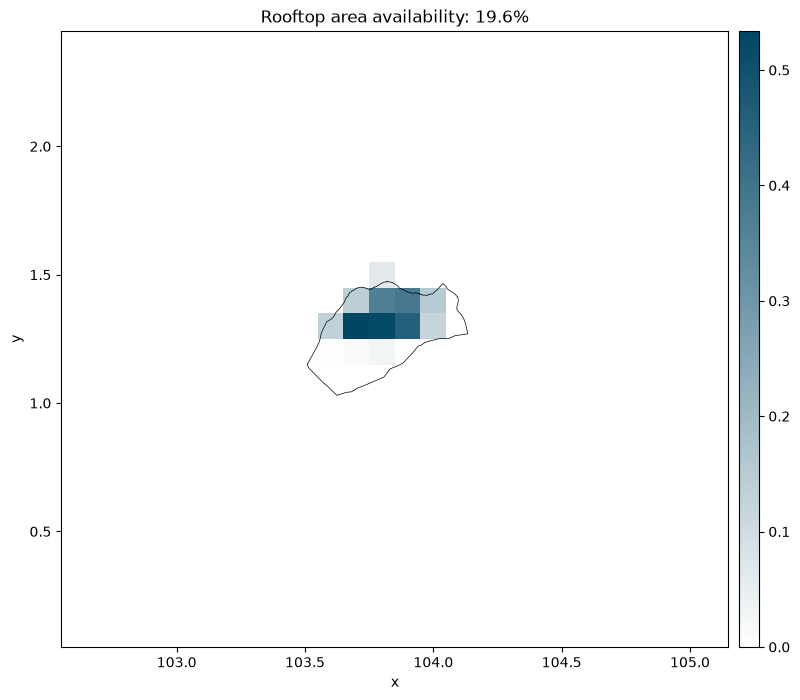

In [27]:
# Controlled by 'run_GIS_analysis_by_region' switch (set in the config cell).
if run_GIS_analysis_by_region:
    combined_potentials, stitched_land, stitched_rooftop, coords_onshore_usable, coords_rooftop_usable, coords_offshore_usable = calculate_potentials_per_region(
        cutout, geo_file, coords_onshore,
        excluder=excluder, cities=cities,
        regions=regions,
        coords_offshore=coords_offshore,
        usable_threshold=usable_threshold, usable_threshold_rooftop=usable_threshold_rooftop,
        offshore_exclude_files=OFFSHORE_EXCLUDE_FILES,
        offshore_exclude_layer=OFFSHORE_EXCLUDE_LAYER,
        offshore_exclude_query=OFFSHORE_EXCLUDE_QUERY,
        pv_cap_per_sqkm=pv_cap_per_sqkm, pv_percent_land_available=pv_percent_land_available,
        wind_cap_per_sqkm=wind_cap_per_sqkm, wind_percent_land_available=wind_percent_land_available,
        rooftop_cap_per_sqkm=rooftop_cap_per_sqkm, rooftop_percent_area_available=rooftop_percent_area_available,
        pv_solar_panel=solar_panel, pv_slope=pv_slope, pv_azimuth=pv_azimuth,
        optimal_tilt=pv_optimal_tilt, rooftop_shares=rooftop_shares,
        output_dir=output_dir, filename=filename, color=map_color,
    )
    combined_potentials

### Offshore wind potential

Reuses the EEZ-clipped, depth-classified offshore cells from `get_coords` (so only actual offshore zones are counted). Singapore's EEZ is tiny, so expect very low totals here - this mainly exercises the pipeline rather than producing meaningful capacity.

In [28]:
# Offshore wind potential per region and depth class. Uses coords_offshore from
# the timeseries step (EEZ + depth). Densities/availability can be a scalar or a
# dict keyed by depth class.
offshore_cap_per_sqkm = 5            # MW/km2
offshore_percent_available = {"shallow": 0.10, "transitional": 0.10, "deep": 0.05}

offshore_df = calculate_offshore_potentials(
    cutout, coords_offshore,
    offshore_cap_per_sqkm=offshore_cap_per_sqkm,
    offshore_percent_available=offshore_percent_available,
)
offshore_df

,region,depth_class,Area [km²],Suitable Area Offshore [km²],Offshore Wind Capacity [GW]
0,SG,transitional,5412.702935,541.270293,2.706351
1,SG,deep,491.967781,24.598389,0.122992


In [29]:
# Offshore potential on USABLE sites only (depth + marine-protected-area exclusion),
# for comparison with the theoretical (depth-only) table above. Writes its own CSV.
if 'coords_offshore_usable' not in dir() or coords_offshore_usable is None:
    coords_offshore_usable = usable_offshore_coords(coords_offshore,
        exclude_files=OFFSHORE_EXCLUDE_FILES, exclude_layer=OFFSHORE_EXCLUDE_LAYER,
        exclude_query=OFFSHORE_EXCLUDE_QUERY)

offshore_df_usable = calculate_offshore_potentials(
    cutout, coords_offshore_usable,
    offshore_cap_per_sqkm=offshore_cap_per_sqkm,
    offshore_percent_available=offshore_percent_available,
)
offshore_df_usable.to_csv(os.path.join(output_dir, f"{filename}_potentials_offshore_usable.csv"), index=False)
offshore_df_usable

,region,depth_class,Area [km²],Suitable Area Offshore [km²],Offshore Wind Capacity [GW]
0,SG,transitional,5412.702935,541.270293,2.706351
1,SG,deep,491.967781,24.598389,0.122992


In [30]:
# Standalone offshore export: pivot offshore_df to one row per region with depth-
# class columns + total, and write to CSV. Only needs offshore_df (run the cell
# above first) - does NOT require the per-region combined run.
_off_wide = offshore_df.pivot_table(index="region", columns="depth_class",
                                    values="Offshore Wind Capacity [GW]",
                                    aggfunc="sum", observed=True)
_off_wide.columns = [f"Offshore Wind {c} [GW]" for c in _off_wide.columns]
_off_wide["Offshore Wind Total [GW]"] = _off_wide.sum(axis=1)
_off_wide = _off_wide.reset_index()
_off_wide.to_csv(os.path.join(output_dir, f"{filename}_potentials_offshore.csv"), index=False)
_off_wide

,region,Offshore Wind transitional [GW],Offshore Wind deep [GW],Offshore Wind Total [GW]
0,SG,2.706351,0.122992,2.829343


usable offshore cells: 48 of 48


<Axes: title={'center': 'Usable offshore cells by depth_class'}>

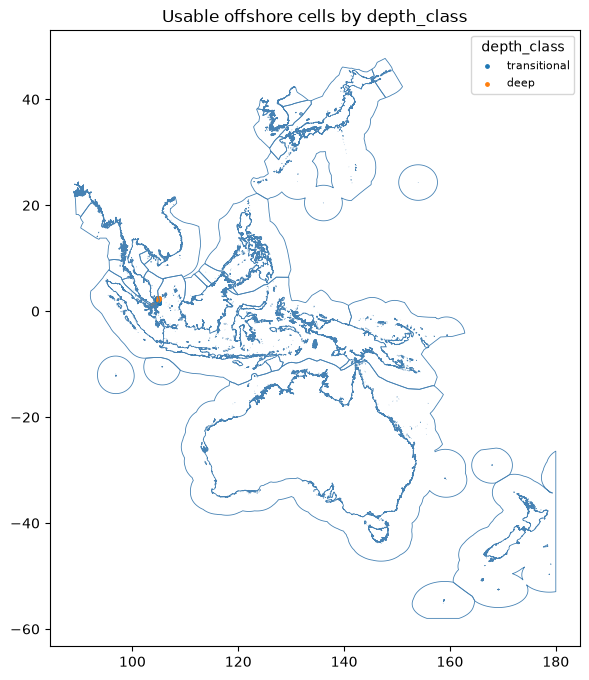

In [31]:
# Usable offshore sites across ALL regions come from the loop above
# (coords_offshore_usable), already filtered by depth AND marine protected areas.
if 'coords_offshore_usable' not in dir() or coords_offshore_usable is None:
    coords_offshore_usable = usable_offshore_coords(coords_offshore,
        exclude_files=OFFSHORE_EXCLUDE_FILES, exclude_layer=OFFSHORE_EXCLUDE_LAYER,
        exclude_query=OFFSHORE_EXCLUDE_QUERY)
print(f"usable offshore cells: {len(coords_offshore_usable)} of {len(coords_offshore)}")

# Offshore wind capacity factors on usable sites only (shallow/transitional/deep):
wind_off_shallow_u, wind_off_trans_u, wind_off_deep_u = wind_offshore_capacity_factors(
    cutout, coords_offshore_usable, offshore_turbine,
    timeframe=timeframe, filename=filename+"_usable",
    write_raw_data=False, output_dir=output_dir)

# Map of the usable offshore cells, coloured by depth class:
plot_offshore_map(coords_offshore_usable, shapes=shapes, offshore_file=offshore_file, color_by="depth_class")

### Capacity-factor timeseries on usable sites only

Restrict the RES timeseries to cells that survive the exclusion layers.
`usable_onshore_coords` keeps cutout cells whose availability > threshold (from the
availability matrix); feed those into the normal PV / onshore-wind functions, which
still split into opt/avg/inf. `usable_offshore_coords` keeps buildable offshore cells
(depth within limits) for the offshore-wind timeseries.

In [32]:
# Usable onshore sites across ALL regions come from the memory-safe loop above
# (coords_onshore_usable). For a quick single-region test instead, use:
#   coords_onshore_usable = usable_onshore_coords(AvailabilityMatrix, coords_onshore)
print(f"usable onshore cells: {len(coords_onshore_usable)} of {len(coords_onshore)}")
print(f"usable rooftop cells: {len(coords_rooftop_usable)} of {len(coords_onshore)}")

# Utility-scale PV on usable land (per-cell optimal tilt if pv_optimal_tilt):
pv_inf_u, pv_avg_u, pv_opt_u = pv_capacity_factors(cutout, coords_onshore_usable, solar_panel,
                                                   pv_slope=pv_slope, pv_azimuth=pv_azimuth,
                                                   optimal_tilt=pv_optimal_tilt,
                                                   timeframe=timeframe, filename=filename+"_usable",
                                                   write_raw_data=False, output_dir=output_dir)

# Rooftop PV: one series per segment (residential / commercial), area-weighted over
# each region's rooftop cells. Writes ..._pv_rooftop_{segment}.csv.
pv_rooftop = pv_rooftop_capacity_factors(cutout, coords_rooftop_usable, solar_panel,
                                         segments=rooftop_segments,
                                         timeframe=timeframe, filename=filename+"_usable",
                                         output_dir=output_dir)

# Onshore wind capacity factors on usable land:
wind_inf_u, wind_avg_u, wind_opt_u = wind_onshore_capacity_factors(cutout, coords_onshore_usable, onshore_turbine,
                                                                   timeframe=timeframe, filename=filename+"_usable",
                                                                   write_raw_data=False, output_dir=output_dir)

usable onshore cells: 11 of 17
usable rooftop cells: 9 of 17


usable offshore cells: 48 of 48


<Axes: title={'center': 'Usable offshore cells by depth_class'}>

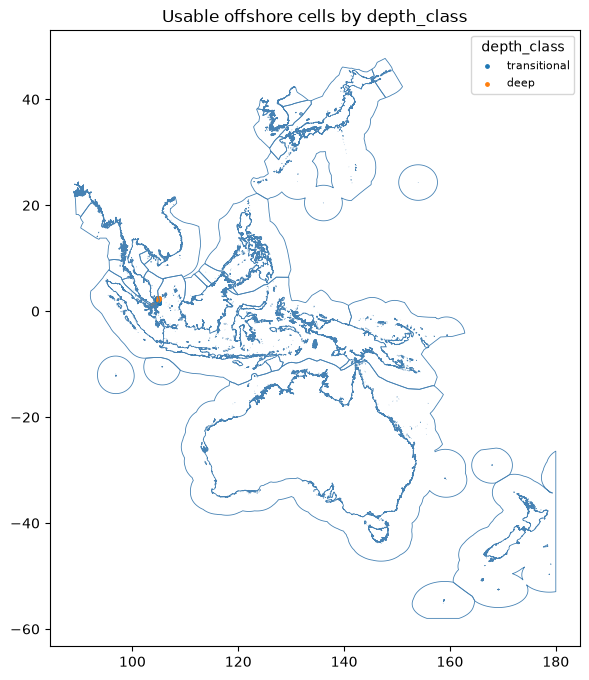

In [33]:
# Usable offshore sites across ALL regions come from the loop above
# (coords_offshore_usable), already filtered by depth AND marine protected areas.
if 'coords_offshore_usable' not in dir() or coords_offshore_usable is None:
    coords_offshore_usable = usable_offshore_coords(coords_offshore,
        exclude_files=OFFSHORE_EXCLUDE_FILES, exclude_layer=OFFSHORE_EXCLUDE_LAYER,
        exclude_query=OFFSHORE_EXCLUDE_QUERY)
print(f"usable offshore cells: {len(coords_offshore_usable)} of {len(coords_offshore)}")

# Offshore wind capacity factors on usable sites only (shallow/transitional/deep):
wind_off_shallow_u, wind_off_trans_u, wind_off_deep_u = wind_offshore_capacity_factors(
    cutout, coords_offshore_usable, offshore_turbine,
    timeframe=timeframe, filename=filename+"_usable",
    write_raw_data=False, output_dir=output_dir)

# Map of the usable offshore cells, coloured by depth class:
plot_offshore_map(coords_offshore_usable, shapes=shapes,
                  offshore_file=offshore_file, color_by="depth_class")

## Plot usable sites

Maps of the developable cells per technology, colour-coded by site-quality class (inf / avg / opt) for onshore and rooftop, and by depth class for offshore. The `category` column is written into the usable-coords CSVs by the memory-safe potentials cell.

**Sensitivity:** the minimum developable share per cell is `usable_threshold` (and `usable_threshold_rooftop`) in the parameters cell. Raise it (e.g. 0.02, 0.03) to drop low-availability cells, then re-run the potentials + this cell.

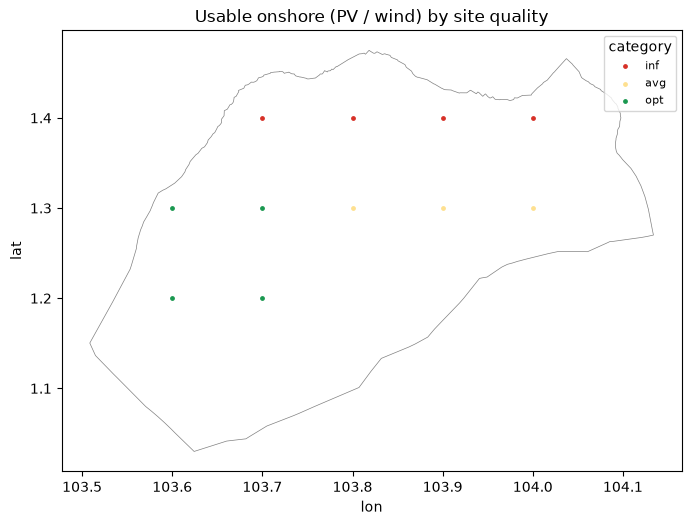

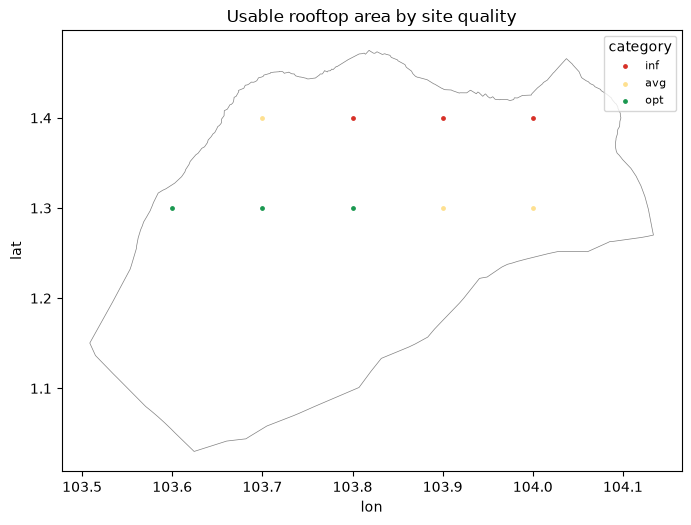

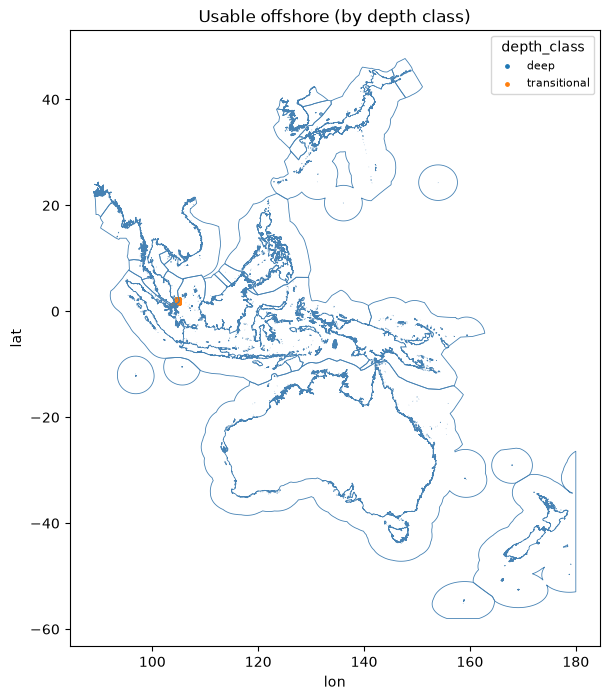

In [34]:
# Maps of usable sites per technology, colour-coded. Onshore/rooftop use the
# site-quality 'category' column (inf/avg/opt) now stored in the usable-coords;
# offshore uses depth class. Guarded so missing/empty layers are skipped.
_region_shapes = shapes if 'shapes' in dir() else None

if 'coords_onshore_usable' in dir() and coords_onshore_usable is not None and len(coords_onshore_usable):
    plot_usable_coords(coords_onshore_usable, shapes=_region_shapes,
                       color_by='category', title='Usable onshore (PV / wind) by site quality')

if 'coords_rooftop_usable' in dir() and coords_rooftop_usable is not None and len(coords_rooftop_usable):
    plot_usable_coords(coords_rooftop_usable, shapes=_region_shapes,
                       color_by='availability', title='Usable rooftop area (built-up share)')

if 'coords_offshore_usable' in dir() and coords_offshore_usable is not None and len(coords_offshore_usable):
    plot_usable_coords(coords_offshore_usable, shapes=_region_shapes,
                       boundary_file=offshore_file, color_by='depth_class',
                       title='Usable offshore (by depth class)')